# Fashion MNIST – ANN (Artificial Neural Network)

**Goal:** Look at a clothing image and predict which item it is (10 classes).

| Label | Item | Label | Item |
|---|---|---|---|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

**Data:** `fashion-mnist_train.csv` (60,000 rows) & `fashion-mnist_test.csv` (10,000 rows).
Each row = `label` + 784 pixel columns (`pixel1 … pixel784`) = 785 columns.

**Model:** 784 → 128 → 24 → 24 → 10 with Dropout + BatchNormalization, softmax output, 30 epochs.

In [1]:
# ===================== 1. IMPORT LIBRARIES =====================
# Updated for new versions of TensorFlow / Keras / matplotlib.
# If a library is missing, install it once in a cell:  !pip install tensorflow seaborn scikit-learn
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn
# ---- Basic Libraries ----
import numpy as np          # numbers & arrays (matrix calculations)
import pandas as pd         # tables (DataFrame) - read CSV, view data

# ---- Visualization libraries ----
import matplotlib.pyplot as plt   # draw images, line graphs
import seaborn as sns             # nicer charts - used for confusion-matrix heatmap
# (pydot removed - it was only needed for drawing model diagrams and is not used here)

# ---- Evaluation library (scikit-learn) ----
from sklearn.metrics import confusion_matrix        # table of correct vs wrong predictions per class
from sklearn.metrics import classification_report   # precision / recall / f1 for each class

# ---- Deep Learning libraries (TensorFlow / Keras) ----
import tensorflow as tf
from tensorflow import keras                         # keras that comes inside TensorFlow
from tensorflow.keras import layers                  # Dense, Dropout, BatchNormalization layers
from tensorflow.keras.datasets import mnist          # built-in handwritten digit dataset (0-9)
from tensorflow.keras.utils import to_categorical    # converts label 3 -> [0,0,0,1,0,0,0,0,0,0] (one-hot)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Load the CSV files
The CSV files must be in the same folder as this notebook; otherwise give the full file path.

In [2]:
# Read train & test CSV files into pandas DataFrames
fashion_train=pd.read_csv("fashion-mnist_train.csv")   # 60000 rows x 785 cols
fashion_test=pd.read_csv("fashion-mnist_test.csv")     # 10000 rows x 785 cols

In [3]:
# (rows, columns) -> 1 label column + 784 pixel columns
fashion_train.shape

(60000, 785)

## 3. Split into X (pixels) and y (label)

In [4]:
X_train_fashion = fashion_train.drop('label',axis = 1)   # all 784 pixel columns (axis=1 -> drop a column)
y_train_fashion = fashion_train['label']                 # only the answer column (0-9)
X_test_fashion = fashion_test.drop('label',axis = 1)     # test pixels
y_test_fashion = fashion_test['label']                   # test answers

## 4. Visualize some images
In the CSV, each image is stored as one row of 784 numbers. It is reshaped to 28×28 only so it can be displayed as a picture.

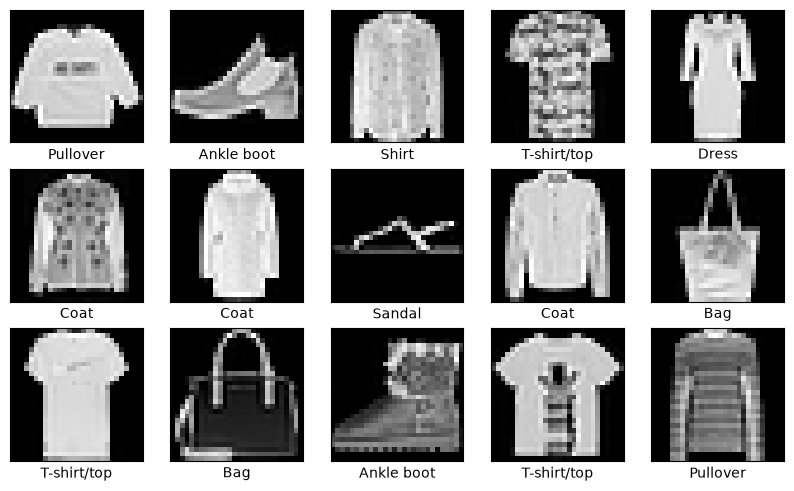

In [5]:
#Reshaping the dataset (only for viewing images)
# .values -> DataFrame to numpy array ; -1 -> "work out the number of images automatically"
x_train_reshape = X_train_fashion.values.reshape(-1,28,28)   # (60000, 28, 28)
x_test_reshape = X_test_fashion.values.reshape(-1,28,28)     # (10000, 28, 28)

#Names of clothing accessories in order (index = label number)
col_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

#Visualizing the images
plt.figure(figsize=(10,10))                       # canvas size
for i in range(15):                               # first 15 images
    plt.subplot(5,5,i+1)                          # 5x5 grid position
    plt.xticks([])                                # hide axis numbers
    plt.yticks([])
    plt.imshow(x_train_reshape[i], cmap='gray')   # show the picture
    plt.xlabel(col_names[y_train_fashion[i]])     # item name below it
plt.show()

## 5. One-hot encode the labels
`9` (Ankle boot) → `[0,0,0,0,0,0,0,0,0,1]`

In [6]:
# number label -> 10-length one-hot vector (needed for categorical_crossentropy)
y_train_fashion = to_categorical(y_train_fashion, num_classes=10)   # (60000, 10)

y_test_fashion = to_categorical(y_test_fashion, num_classes=10)     # (10000, 10)

## 6. Build, compile and train the model
```
Input 784 → Dense 128 (ReLU) → Dropout 0.3 → BatchNorm
          → Dense 24  (ReLU) → Dropout 0.3 → BatchNorm
          → Dense 24  (ReLU) → Dropout 0.3 → BatchNorm
          → Dense 10  (softmax)
```
- **Dropout(0.3)** – at every training step, randomly switches off 30% of the neurons, so the model generalises instead of memorising (less overfitting).
- **BatchNormalization** – each layer's outputs are re-scaled to a stable range → faster, steadier training (this also helps because pixels here are 0–255, not scaled).
- **softmax** – 10 scores add up to 1 → each score = probability of that class.

In [7]:
#Creating base neural network
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(784,)),  # hidden 1: 128 neurons, input = 784 pixels
    layers.Dropout(0.3),                                       # switch off 30% neurons randomly (training only)
    layers.BatchNormalization(),                               # normalise outputs of this layer
    layers.Dense(24, activation='relu'),                       # hidden 2: 24 neurons
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(24, activation='relu'),                       # hidden 3: 24 neurons
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(10,activation='softmax'),                     # output: 10 classes, probabilities sum to 1
])

#Compiling the model
model.compile(loss="categorical_crossentropy",   # loss for one-hot multi-class labels
              optimizer="adam",                  # weight-update algorithm
              metrics = ['accuracy'])            # print accuracy each epoch

#Fitting the model
history=model.fit(X_train_fashion, y_train_fashion,                   # training pixels & answers
                  batch_size=100,                                     # 100 images per step -> 600 steps/epoch
                  epochs=30,                                          # 30 full passes over the data
                  validation_data=(X_test_fashion, y_test_fashion))   # check on test data after each epoch
# Train accuracy (~0.83) is LOWER than val accuracy (~0.87) here - that's normal with Dropout,
# because neurons are switched off only during training, not during testing.

C:\Users\nisha\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.6230 - loss: 1.1247 - val_accuracy: 0.8286 - val_loss: 0.5196
Epoch 2/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7597 - loss: 0.7238 - val_accuracy: 0.8479 - val_loss: 0.4511
Epoch 3/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7860 - loss: 0.6494 - val_accuracy: 0.8492 - val_loss: 0.4395
Epoch 4/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7978 - loss: 0.6170 - val_accuracy: 0.8543 - val_loss: 0.5051
Epoch 5/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8005 - loss: 0.5968 - val_accuracy: 0.8507 - val_loss: 0.4182
Epoch 6/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8120 - loss: 0.5697 - val_accuracy: 0.8636 - val_loss: 0.4036
Epoch 7/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8135 - loss: 0.5614 - val_accuracy: 0.8601 - val_loss: 0.4055
Epoch 8/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8153 - loss: 0.5547 - val_accuracy: 0.

## 7. Evaluate on the test set

In [8]:
# Run the model on 10,000 test images -> [loss, accuracy]
test_loss_fashion, test_acc_fashion = model.evaluate(X_test_fashion, y_test_fashion)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8734 - loss: 0.3815


In [9]:
# 0.8714 = 87.14% of test clothes predicted correctly
print('Fashion MNIST Test accuracy:', round(test_acc_fashion,4))

Fashion MNIST Test accuracy: 0.8734


## 8. Predictions, confusion matrix & classification report

In [10]:
#Predicting the labels-Fashion
y_predict_fash = model.predict(X_test_fashion)            # (10000, 10) probabilities
y_predict_fash=np.argmax(y_predict_fash, axis=1)          # highest probability index = predicted class
y_test_fash_eval=np.argmax(y_test_fashion, axis=1)        # one-hot actual labels back to 0-9

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


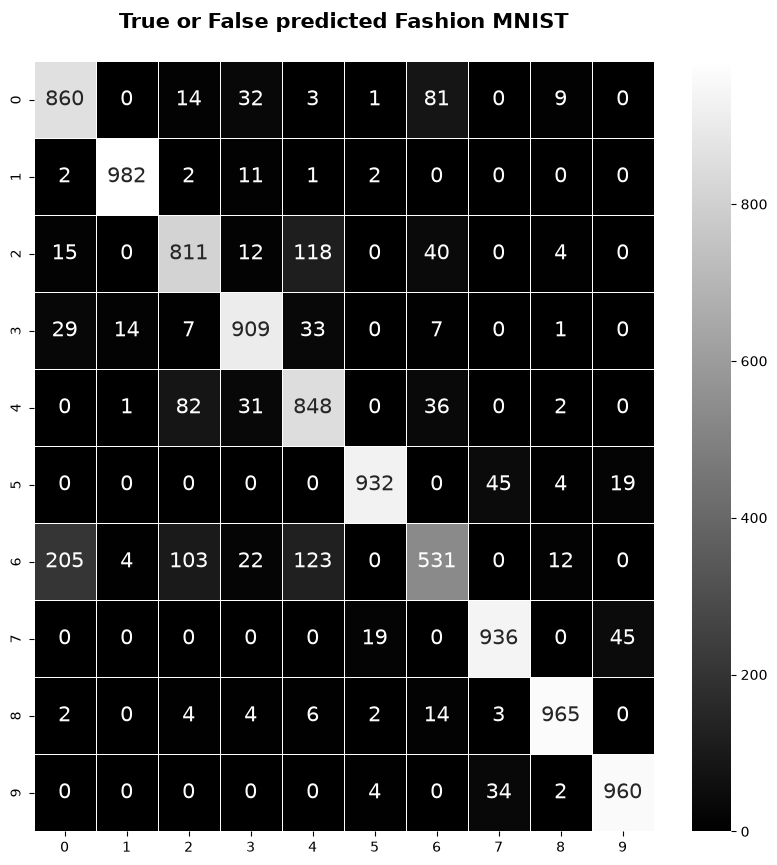

In [11]:
# Confusion matrix: rows = actual item, columns = predicted item, diagonal = correct
con_mat=confusion_matrix(y_test_fash_eval,y_predict_fash)
plt.style.use('seaborn-v0_8-deep')     # chart style (old matplotlib name was 'seaborn-deep')
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,annot=True,annot_kws={'size': 15},linewidths=0.5,fmt="d",cmap="gray")
#            annot=True -> numbers inside boxes, fmt="d" -> whole numbers, cmap -> colours
plt.title('True or False predicted Fashion MNIST\n',fontweight='bold',fontsize=15)
plt.show()
# Common mix-ups: Shirt(6) vs T-shirt(0) / Pullover(2) / Coat(4) - they look similar.

In [12]:
from sklearn.metrics import classification_report

# precision / recall / f1 for each of the 10 items
print(classification_report(y_test_fash_eval,y_predict_fash))
# Class 6 (Shirt) usually has the lowest score; class 1 (Trouser), 8 (Bag) the highest.

              precision    recall  f1-score   support

           0       0.77      0.86      0.81      1000
           1       0.98      0.98      0.98      1000
           2       0.79      0.81      0.80      1000
           3       0.89      0.91      0.90      1000
           4       0.75      0.85      0.80      1000
           5       0.97      0.93      0.95      1000
           6       0.75      0.53      0.62      1000
           7       0.92      0.94      0.93      1000
           8       0.97      0.96      0.97      1000
           9       0.94      0.96      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



## 9. Training curves

In [13]:
# Keys recorded during training
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


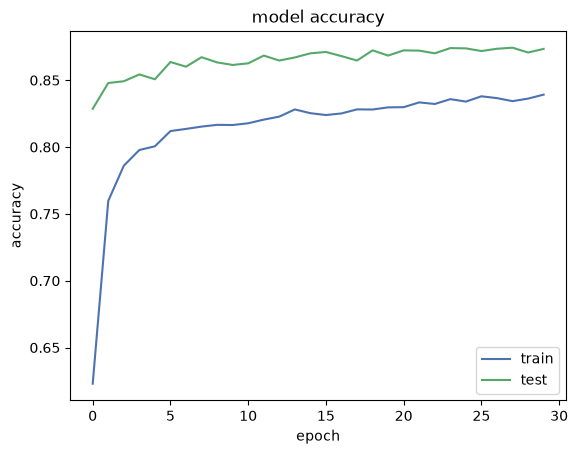

In [14]:
# ---- Accuracy curve: train vs test for every epoch ----
plt.plot(history.history['accuracy'])       # training accuracy per epoch
plt.plot(history.history['val_accuracy'])   # validation (test) accuracy per epoch
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()
# Both lines going UP together  = model is learning well
# Train UP but test FLAT/DOWN   = overfitting (memorising training data)

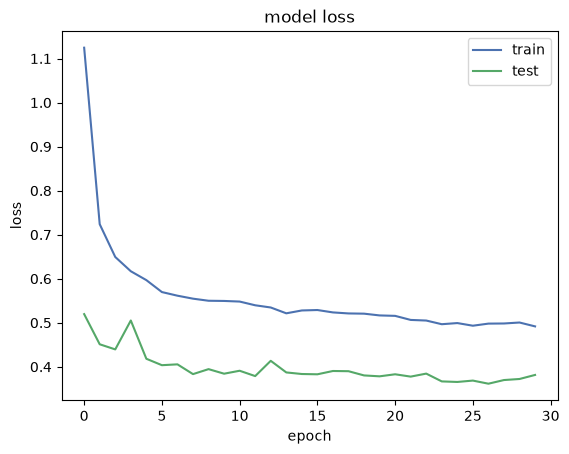

In [15]:
# ---- Loss curve: train vs test for every epoch ----
plt.plot(history.history['loss'])       # training loss (error) per epoch
plt.plot(history.history['val_loss'])   # validation (test) loss per epoch
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()
# Loss should go DOWN. If val_loss starts going UP while train loss goes down -> overfitting.

## 10. Predict a single image
`X_test_fashion.loc[[0],:]` → first test row as a DataFrame (1 × 784). `.values` → numpy array.

⚠ **Fix made here:** the original code showed `x_train_reshape[0]` (a **train** image) but the prediction & "Actual" label were for **test** image 0. Changed to `x_test_reshape[0]` so the picture matches. Run this cell again to get the new output.

In [16]:
#tf.expand_dims(X_test_digit[0])
y_predict = model.predict(X_test_fashion.loc[[0],:].values)   # [[0]] keeps it 2D -> shape (1, 784)
y_predict=np.argmax(y_predict, axis=1) # Here we get the index of maximum value in the encoded vector
y_test_digit_eval=np.argmax(y_test_fashion, axis=1)           # actual labels as numbers

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


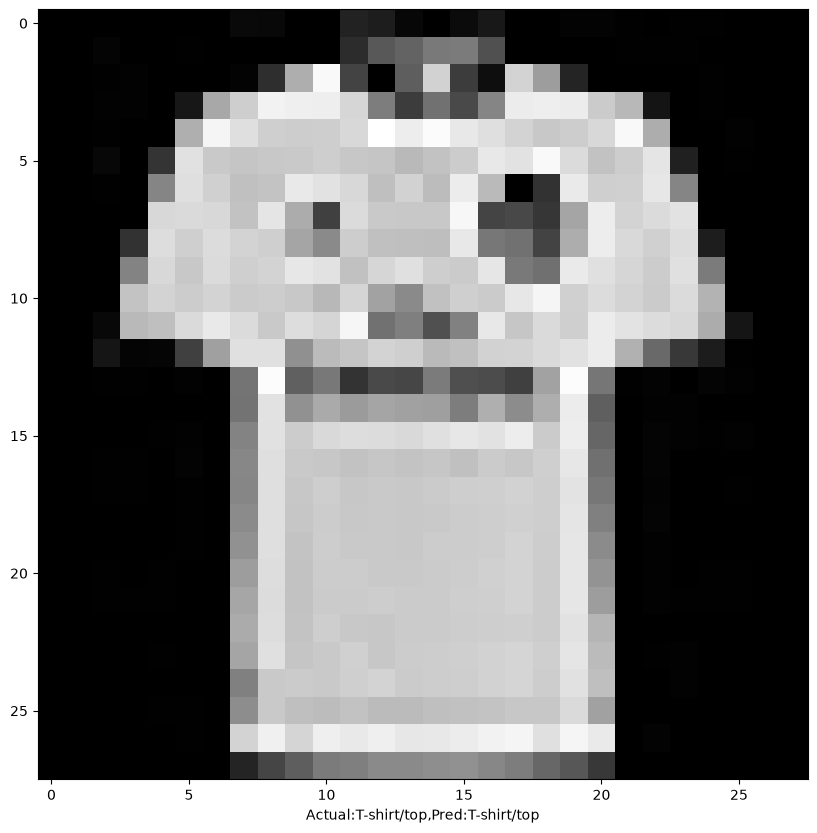

In [17]:
#Names of clothing accessories in order
col_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

#Visualizing the images
plt.figure(figsize=(10,10))

plt.imshow(x_test_reshape[0], cmap='gray')    # FIXED: was x_train_reshape[0] -> must be TEST image 0
plt.xlabel("Actual:{},Pred:{}".format(col_names[np.argmax(y_test_fashion[0])],   # real item
                                      col_names[y_predict[0]]))                  # model's guess
plt.show()

## 11. Summary & next steps
| | Result |
|---|---|
| Test accuracy | **87.14 %** |
| Epochs | 30 |

**Ideas to improve:**
1. Scale pixels to 0–1 with `X_train_fashion / 255.0`.
2. Try larger hidden layers (24 → 64 or 128); 24 neurons is quite small.
3. Use a **CNN** (Conv2D layers) for images; it usually reaches 90%+ accuracy. A good next step.